# 第 7 课 · 巢式 Logit：市场份额、识别与替代

连锁商店的每个市场都销售三款咖啡和三款茶饮，顾客还可以选择不购买。如果咖啡 A 涨价，它流失的销量会更多地转向其他咖啡，还是转向茶饮？我们只有每个市场的价格、产品特征和销量份额。如何估计一个允许组内替代更强的需求模型？

**建议配合第 7–8 周学习，配套自学约 6–8 小时。** 这一课接在[市场份额反演与 IV/GMM](06-aggregate-logit-iv-gmm.ipynb)之后。你将从选择概率推出可估计方程，用两项排除工具变量共同识别价格系数和巢参数，并在基准份额相同的条件下比较巢式 Logit 与普通 Logit 的替代预测。

## 1. 从产品效用到两层选择概率

记 $t$ 为市场，$j$ 为商品，$g(j)$ 为该商品所在的组，称为**巢**（nest）。组别事先给定，互不重叠。不购买是单独的外部选项 $0$，平均效用归一为 $\delta_{0t}=0$。市场中所有顾客共享产品的平均效用

$$
\delta_{jt}=\beta_0+\beta_x x_{jt}-\alpha(p_{jt}-8)+\xi_{jt},\qquad j>0.
$$

这里 $\xi_{jt}$ 是研究者未观测到的产品–市场效用。顾客选择时还有个体层面的随机效用冲击。巢式 Logit 允许同一顾客对同巢商品的个体冲击相关，这与市场层面的 $\xi_{jt}$ 是两层不同的随机因素。我们用统一的差异度参数 $\lambda=1-\sigma\in(0,1]$。$\sigma$ 越大，同巢商品的个体效用冲击关联越强。$\sigma$ 是模型参数，本身不等于两种产品冲击的相关系数。

暂省略市场下标，令 $a_j=\exp(\delta_j)$。巢式 Logit 的广义极值（GEV）生成函数可写为

$$
G(a)=a_0+\sum_g\left(\sum_{k\in g}a_k^{1/\lambda}\right)^\lambda.
$$

GEV 的份额公式是 $s_j=a_j(\partial G/\partial a_j)/G$。用链式法则求导，设 $D_g=\sum_{k\in g}\exp(\delta_k/\lambda)$，得到分子 $\exp(\delta_j/\lambda)D_g^{\lambda-1}$。把它乘除同一个 $D_g$，就能把份额写为条件份额乘以巢份额：

$$
\begin{aligned}
I_g&=\log D_g=\log\sum_{k\in g}\exp(\delta_k/\lambda),\\
s_{j\mid g}&=\exp(\delta_j/\lambda-I_g),\\
s_g&=\frac{\exp(\lambda I_g)}{1+\sum_h\exp(\lambda I_h)},\qquad
s_0=\frac{1}{1+\sum_h\exp(\lambda I_h)},\\
s_j&=s_{j\mid g(j)}s_{g(j)}.
\end{aligned}
$$

$I_g$ 是本记号下的包容值（inclusive value），$\lambda I_g$ 是巢在上层概率中的效用项。这个分解描述份额，顾客只需在一次选择中挑出效用最高的一项。同巢两商品的份额比为 $\exp[(\delta_j-\delta_k)/\lambda]$。跨巢份额比还会随两个巢中其他商品的效用变化，因此[第三课](03-multinomial-logit.ipynb)的全局 IIA 不再成立。同巢仍有 IIA，巢的划分也要有经济依据。若 $\sigma=0$，则 $\lambda=1$，巢项相消，$s_j$ 退化为普通 Logit 份额。 [Train（2009），§4.2](https://eml.berkeley.edu/books/choice2nd/Ch04_p76-96.pdf)

## 2. 份额反演与识别条件

销量份额的分母应包括所有潜在顾客。令 $s_g=\sum_{k\in g}s_k$，$s_{j\mid g}=s_j/s_g$，$s_0=1-\sum_{k>0}s_k$。由于 $\log(s_g/s_0)=\lambda I_g$，而 $\delta_j=\lambda(\log s_{j\mid g}+I_g)$，两式合并给出

$$
\begin{aligned}
\log(s_{jt}/s_{0t})
&=\delta_{jt}+\sigma\log(s_{j\mid g,t})\\
&=\beta_0+\beta_x x_{jt}-\alpha(p_{jt}-8)
        +\sigma\log(s_{j\mid g,t})+\xi_{jt}.
\end{aligned}
$$

如果知道 $\sigma$，就可以用观测份额恢复 $\delta_{jt}$。这个显式反演要求产品份额和外部份额为正。接下来先用模型的总体份额来练习，以便把识别问题与有限顾客样本中的份额测量问题分开。 [Berry（1994），式（23）—（26）](https://www.its.caltech.edu/~mshum/gradio/papers/Berry1994.pdf)

- **价格为什么内生？** 较高的 $\xi_{jt}$ 往往会让商品定价更高，因此价格与需求误差相关。
- **组内份额为什么也内生？** 价格给定时，自己的 $\xi_{jt}$ 上升会提高自己的组内份额。由 $\log s_{j\mid g}=\delta_j/\lambda-I_g$ 可得导数 $(1-s_{j\mid g})/\lambda>0$。所以组内份额本身就是效用冲击作用下的结果。

设 $d_{jt}=(p_{jt}-8,\ \log s_{j\mid g,t})'$。从 $d_{jt}$ 和排除工具 $z_{jt}$ 中净掉常数和本品特征后，记为 $\widetilde d_{jt}$ 和 $\widetilde z_{jt}$。估计需要满足两类条件：

$$
E[z_{jt}\xi_{jt}]=0,\qquad
\operatorname{rank} E[\widetilde z_{jt}\widetilde d_{jt}']=2.
$$

常数与本品特征也须满足相应的外生性矩条件。前者来自排除限制和外生性，后者要求有两条可区分的工具变量变动。某项工具可以同时影响价格和组内份额。重点在于工具矩阵能独立预测这两个变量的不同方向。

## 3. 模拟市场–商品数据

每个市场有六款商品，前三款是咖啡，后三款是茶饮。设 $x_{jt}$ 为本品可观测特征，$c_{jt}$ 为本品成本冲击，$\eta_{jt}$、$b_t$ 和 $v_{jt}$ 分别为需求的产品–市场分量、需求的市场共同分量及附加报价冲击。它们由相互独立的标准正态抽样给出。模拟需求误差与报价为

$$
\xi_{jt}=0.45\eta_{jt}+0.22b_t,\qquad
p_{jt}=8+0.40x_{jt}+0.90c_{jt}+1.10\xi_{jt}+0.30v_{jt}.
$$

这是一条模拟报价规则。每个市场的 $b_t$ 同时进入多款商品的需求误差，所以后续用市场聚类标准误。两个排除工具是本品成本冲击，以及同巢其他商品特征的平均值。

| 排除工具 | 为什么能移动右侧变量 | 为什么可排除在本品效用之外 |
| --- | --- | --- |
| 本品成本冲击 $c_{jt}$ | 报价规则直接使用它，价格随之影响组内份额 | 模拟时成本冲击独立于 $\xi_{jt}$，效用方程也没有直接成本项 |
| 同巢其他商品的平均特征 $\bar x_{-j,g,t}$ | 其他商品的效用会改变组内概率的分母 | 本品效用只含本品特征，模拟中的产品特征独立于需求误差 |

在真实数据中，促销可能同时改变成本和陈列，竞争商品可能因商家预见共同需求而增加。此时要重新判断排除条件。第一阶段可以检查工具是否移动右侧变量，工具为什么外生则要靠数据和制度背景说明。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import logsumexp

rng = np.random.default_rng(707)
market_count = 800
nest_index = np.array([0, 0, 0, 1, 1, 1])
products_per_market = len(nest_index)
shape = (market_count, products_per_market)
true_coefficients = np.array([0.10, 0.85, -0.55, 0.55])

product_feature = rng.normal(size=shape)
cost_shock = rng.normal(size=shape)
demand_error = 0.45 * rng.normal(size=shape) + 0.22 * rng.normal(size=(market_count, 1))
centered_price = (
    0.40 * product_feature + 0.90 * cost_shock
    + 1.10 * demand_error + 0.30 * rng.normal(size=shape)
)
intercept, feature_coefficient, price_coefficient, sigma_true = true_coefficients
mean_utility = (
    intercept + feature_coefficient * product_feature
    + price_coefficient * centered_price + demand_error
)


def nested_log_shares(delta, group_index, sigma):
    """返回产品、外部选项和组内条件份额的对数。"""
    if not 0 <= sigma < 1:
        raise ValueError("计算份额要求 0 <= sigma < 1")
    delta = np.atleast_2d(delta)
    scale = 1 - sigma
    _, groups = np.unique(group_index, return_inverse=True)
    scaled_utility = delta / scale
    inclusive_values = np.column_stack([
        logsumexp(scaled_utility[:, groups == group], axis=1)
        for group in range(groups.max() + 1)
    ])
    log_outside = -logsumexp(
        np.column_stack((np.zeros(len(delta)), scale * inclusive_values)), axis=1
    )
    log_within = scaled_utility - inclusive_values[:, groups]
    log_product = log_within + scale * inclusive_values[:, groups] + log_outside[:, None]
    return log_product, log_outside, log_within


log_product, log_outside, log_within = nested_log_shares(
    mean_utility, nest_index, sigma_true
)
observed_shares = np.exp(log_product)
outside_shares = 1 - observed_shares.sum(axis=1)
assert np.all(outside_shares > 0) and np.all(observed_shares > 0)
assert np.allclose(outside_shares, np.exp(log_outside))

# 估计时从份额重建因变量和内生变量。模拟中的真实效用只用于校验。
same_nest = (nest_index[:, None] == nest_index).astype(int)
same_nest_rivals = same_nest - np.eye(products_per_market, dtype=int)
rival_feature = product_feature @ same_nest_rivals / same_nest_rivals.sum(axis=0)
observed_nest_shares = observed_shares @ same_nest
within_share = observed_shares / observed_nest_shares
dependent = np.log(observed_shares / outside_shares[:, None]).ravel()
within_log = np.log(within_share).ravel()
assert np.allclose(dependent - sigma_true * within_log, mean_utility.ravel())

print(f"{market_count:,} 个市场，共 {len(dependent):,} 条市场–商品记录")
print(f"报价范围（元） [{8 + centered_price.min():.2f}, {8 + centered_price.max():.2f}]")
print(f"外部份额范围 [{outside_shares.min():.3f}, {outside_shares.max():.3f}]")

800 个市场，共 4,800 条市场–商品记录
报价范围（元） [4.11, 12.03]
外部份额范围 [0.047, 0.374]


## 4. 两个内生变量的第一阶段

令 $W=[1,x]$，$D=[p-8,\log s_{j\mid g}]$，$Q=[c,\bar x_{-j,g}]$。先从 $D$ 和 $Q$ 去掉 $W$ 的线性投影，再用剩余工具分别拟合两列剩余内生变量，得到 $\widehat{\widetilde D}=P_{\widetilde Q}\widetilde D$。

**只看两个第一阶段的 $R^2$ 会漏掉什么？** 如果两个拟合值都由同一条工具变动带来，它们可能都与原变量很相关，仍无法分别识别两个系数。我们做两个几何检查。

1. 把每列拟合值对另一列拟合值投影，取剩余部分的长度，除以原内生变量净掉 $W$ 后的长度。这个比值显示各变量有多少独立于另一拟合方向的预测信号。
2. 对 $\widetilde Q$ 和 $\widetilde D$ 分别取正交基，求两个正交基叉积的奇异值，即典型相关。第二个值接近零时，只有一条可辨别的共同变动方向。

下面也演示只保留成本工具的情况。这些是描述性检查，多内生变量的正式弱工具诊断要使用适合抽样结构的统计量，不能直接把单方程的 $F$ 阈值用在这里。 [Sanderson 与 Windmeijer（2016）](https://doi.org/10.1016/j.jeconom.2015.06.004)

In [2]:
controls = np.column_stack((np.ones(len(dependent)), product_feature.ravel()))
endogenous = np.column_stack((centered_price.ravel(), within_log))
excluded = np.column_stack((cost_shock.ravel(), rival_feature.ravel()))
regressors = np.column_stack((controls, endogenous))
instruments = np.column_stack((controls, excluded))


def partial_out(values, basis):
    coefficients = np.linalg.lstsq(basis, values, rcond=None)[0]
    return values - basis @ coefficients


partial_endogenous = partial_out(endogenous, controls)
partial_excluded = partial_out(excluded, controls)
instrument_basis, _ = np.linalg.qr(partial_excluded)
endogenous_basis, _ = np.linalg.qr(partial_endogenous)
first_stage = instrument_basis @ (instrument_basis.T @ partial_endogenous)
canonical_correlations = np.linalg.svd(
    instrument_basis.T @ endogenous_basis, compute_uv=False
)
print("两个典型相关", np.round(canonical_correlations, 3))
print("内生变量        第一阶段 R²  去掉另一拟合方向后的相对长度")
for column, variable in enumerate(("Price", "Log within")):
    raw = partial_endogenous[:, column]
    fitted = first_stage[:, column]
    unique_fitted_part = partial_out(fitted, first_stage[:, [1 - column]])
    fit_ratio = np.linalg.norm(fitted) / np.linalg.norm(raw)
    conditional_ratio = np.linalg.norm(unique_fitted_part) / np.linalg.norm(raw)
    print(f"{variable:<15} {fit_ratio**2:>7.3f} {conditional_ratio:>23.3f}")

cost_only = (
    partial_excluded[:, :1]
    @ np.linalg.lstsq(partial_excluded[:, :1], partial_endogenous, rcond=None)[0]
)
cost_only_r2 = (cost_only**2).sum(axis=0) / (partial_endogenous**2).sum(axis=0)
print("只用成本工具的第一阶段 R²", np.round(cost_only_r2, 3))
print("只用成本工具的拟合矩阵秩", np.linalg.matrix_rank(cost_only))

两个典型相关 [0.869 0.495]
内生变量        第一阶段 R²  去掉另一拟合方向后的相对长度
Price             0.674                   0.548
Log within        0.519                   0.481
只用成本工具的第一阶段 R² [0.673 0.286]
只用成本工具的拟合矩阵秩 1


## 5. 2SLS 与市场聚类标准误

令 $X=[W,D]$，$Z=[W,Q]$。第一阶段计算 $\widehat X=P_Z X$，第二阶段回归 $y=\log(s_j/s_0)$ 对 $\widehat X$。实际实现只解两个最小二乘问题，不存储巨大的投影矩阵。标准误用原始回归变量的结构残差 $\hat\xi=y-X\hat\theta$，并将同一市场的得分加总后再取外积。

$$
\widehat{\operatorname{Var}}(\hat\theta)
=A^{-1}\left(\sum_t u_tu_t'\right)A^{-1},\qquad
A=\widehat X'\widehat X,\quad u_t=\sum_{j\in t}\widehat X_{jt}'\hat\xi_{jt}.
$$

这里用未做小样本修正的聚类夹心标准误。其推断依赖市场数充分、不同市场独立、工具有效及识别不弱。本例有两个内生变量和两个排除工具，是恰好识别的模型。样本矩近似为零是估计方程的结果，不提供对排除条件的独立检验。

In [3]:
def fit_2sls(y, x, z, market_count, products_per_market):
    """用两次最小二乘和按市场的聚类夹心估计需求方程。"""
    if np.linalg.matrix_rank(z) < z.shape[1]:
        raise ValueError("工具矩阵的列线性相关")
    projected_x = z @ np.linalg.lstsq(z, x, rcond=None)[0]
    if np.linalg.matrix_rank(projected_x) < x.shape[1]:
        raise ValueError("工具预测的独立方向少于待估系数")
    estimate = np.linalg.lstsq(projected_x, y, rcond=None)[0]
    residual = y - x @ estimate
    scores = (projected_x * residual[:, None]).reshape(
        market_count, products_per_market, x.shape[1]
    ).sum(axis=1)
    bread = np.linalg.solve(projected_x.T @ projected_x, np.eye(x.shape[1]))
    covariance = bread @ (scores.T @ scores) @ bread
    return estimate, np.sqrt(covariance.diagonal()), residual


ols = np.linalg.lstsq(regressors, dependent, rcond=None)[0]
iv, standard_errors, iv_residual = fit_2sls(
    dependent, regressors, instruments, market_count, products_per_market
)
print(f"{'Coefficient':<16} {'Truth':>8} {'OLS':>8} {'2SLS':>8} {'Cluster SE':>12}")
for name, truth, ols_value, iv_value, se in zip(
    ("Intercept", "Own feature", "Price (-alpha)", "Nest (sigma)"),
    true_coefficients, ols, iv, standard_errors,
):
    print(f"{name:<16} {truth:>8.3f} {ols_value:>8.3f} {iv_value:>8.3f} {se:>12.3f}")

max_moment = np.max(np.abs(instruments.T @ iv_residual / len(iv_residual)))
assert max_moment < 1e-10
assert np.allclose(iv, np.linalg.solve(instruments.T @ regressors, instruments.T @ dependent))
if not 0 <= iv[-1] < 1 or iv[-2] >= 0:
    raise RuntimeError("IV 估计超出本课反事实的参数范围，请先检查设定及识别")

Coefficient         Truth      OLS     2SLS   Cluster SE
Intercept           0.100    0.423    0.106        0.025
Own feature         0.850    0.570    0.855        0.020
Price (-alpha)     -0.550   -0.238   -0.549        0.013
Nest (sigma)        0.550    0.715    0.550        0.012


在这份模拟中，OLS 的价格系数为 −0.238，巢参数为 0.715，2SLS 则约为 −0.549 和 0.550，接近模拟真值。成本工具单独能预测两个变量，但其拟合矩阵只有一个方向。加入同巢其他商品特征后，两个典型相关约为 0.869 和 0.495，两个变量各保留独立的预测成分。这份样本的结果说明了设定中的工具怎样工作，不能替代实证应用中的识别论证。

## 6. 让咖啡 A 涨价，需求流向哪里？

用样本的第二个市场做局部政策实验。比较两种模型时，先为各模型分别反演能复现**同一组基准产品份额与外部份额**的平均效用。再对两种模型施加相同的效用变动 $-\hat\alpha\Delta p_A$，即咖啡 A 涨价 0.75 元，其他价格、产品与需求冲击保持固定。普通 Logit 只用于同基准比较，其价格系数与巢式 Logit 相同。

设咖啡 A 的份额损失 $L=s_A^{\mathrm{base}}-s_A^{\mathrm{new}}>0$，对任一承接选项集合 $S$，定义承接比例

$$
\frac{\sum_{k\in S}(s_k^{\mathrm{new}}-s_k^{\mathrm{base}})}{L}.
$$

这是有限价格变动的份额账。图中的百分比分母是咖啡 A 流失的份额，表中的百分点分母是全部潜在顾客。

第 2 个市场，咖啡 A 从 7.24 涨到 7.99 元
Model             Coffee A loss   Other coffee        Tea    Outside
Logit                     6.69           1.37       2.92       2.41
Nested Logit             10.70           5.95       2.60       2.14
表内单位均为百分点。


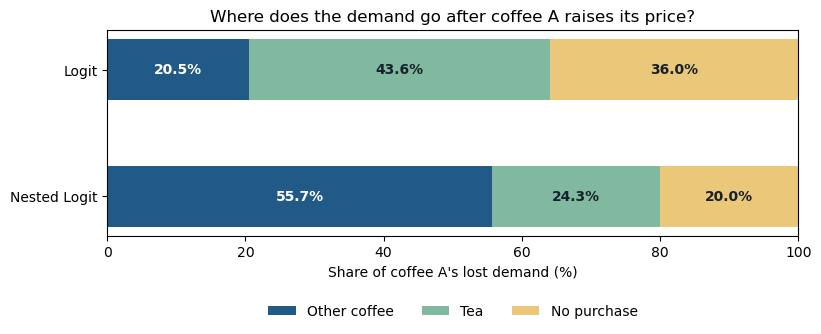

In [4]:
market_example = 1  # Python 从 0 编号
changed_product = 0  # 咖啡 A
price_increase = 0.75
baseline_price = 8 + centered_price[market_example, changed_product]
sigma_iv = iv[-1]
slope_iv = iv[-2]
baseline_log_ratio = dependent.reshape(shape)[market_example]
baseline_within = within_log.reshape(shape)[market_example]
baseline = np.r_[observed_shares[market_example], outside_shares[market_example]]
in_same_nest = nest_index == nest_index[changed_product]
other_same_nest = in_same_nest & (np.arange(products_per_market) != changed_product)


def predict_shares(delta, sigma):
    log_s, log_s0, _ = nested_log_shares(delta, nest_index, sigma)
    return np.r_[np.exp(log_s[0]), np.exp(log_s0[0])]


allocations = []
print(f"第 {market_example + 1} 个市场，咖啡 A 从 {baseline_price:.2f} 涨到 {baseline_price + price_increase:.2f} 元")
print(f"{'Model':<16} {'Coffee A loss':>14} {'Other coffee':>14} {'Tea':>10} {'Outside':>10}")
for label, model_sigma in (("Logit", 0.0), ("Nested Logit", sigma_iv)):
    base_delta = baseline_log_ratio - model_sigma * baseline_within
    assert np.allclose(predict_shares(base_delta, model_sigma), baseline)
    new_delta = base_delta.copy()
    new_delta[changed_product] += slope_iv * price_increase
    changes = predict_shares(new_delta, model_sigma) - baseline
    loss = -changes[changed_product]
    gains = np.array([
        changes[:-1][other_same_nest].sum(),
        changes[:-1][~in_same_nest].sum(),
        changes[-1],
    ])
    assert loss > 0 and np.all(gains > 0) and np.isclose(gains.sum(), loss)
    allocations.append(100 * gains / loss)
    print(f"{label:<16} {100 * loss:>13.2f} {100 * gains[0]:>14.2f} "
          f"{100 * gains[1]:>10.2f} {100 * gains[2]:>10.2f}")
print("表内单位均为百分点。")

fig, ax = plt.subplots(figsize=(8.1, 3.1), layout="constrained")
colors = ("#215a87", "#80b99f", "#ebc77a")
categories = ("Other coffee", "Tea", "No purchase")
for row, shares_of_loss in enumerate(allocations):
    start = 0
    for i, (category, value) in enumerate(zip(categories, shares_of_loss)):
        ax.barh(row, value, left=start, height=0.48, color=colors[i],
                label=category if row == 0 else None)
        ax.text(start + value / 2, row, f"{value:.1f}%", ha="center", va="center",
                color="white" if i == 0 else "#17212b", fontweight="semibold")
        start += value
ax.set_yticks([0, 1], ["Logit", "Nested Logit"])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of coffee A's lost demand (%)")
ax.set_title("Where does the demand go after coffee A raises its price?")
ax.legend(ncols=3, loc="lower center", bbox_to_anchor=(0.5, -0.46), frameon=False)
plt.show()

这个市场中，咖啡 A 涨价后，巢式 Logit 预测其他咖啡承接约 **55.7%** 的流失份额，普通 Logit 预测约 **20.5%**。两种模型的基准份额相同，差异来自它们对替代的设定。表中四舍五入后的承接量相加，可能与 A 的份额损失相差 0.01 个百分点。

## 7. 进一步学习

1. **推导。** 从 $G(a)$ 分别推导不购买、一个商品、一个巢的份额。证明 $\sigma=0$ 退化为普通 Logit，并解释同巢 IIA 怎样约束咖啡 B 和咖啡 C 的替代关系。
2. **双内生变量。** 只保留成本工具并运行估计，解释报错。在数据生成时把 $0.35c_{jt}$ 加入平均效用，保持报价规则和估计式不变。比较偏离真值的程度，并记录价格第一阶段的 $R^2$，解释为什么相关性诊断无法发现这类排除限制失效。
3. **有限变动与导数。** 将提价幅度从 0.75 改为 0.0001 元。对同巢的 $k\ne A$，推导 $\partial\log s_k/\partial\delta_A=-s_A-\sigma s_{A\mid g}/(1-\sigma)$。将对数份额的差分除以 $-\hat\alpha\Delta p_A$ 核对该式，并与跨巢的 $-s_A$ 比较。按百分点列出基准与新情景的份额差，再用两者的变化量验证承接比例。
4. **模型诊断。** 从已有数据中拿出两个咖啡和一个茶饮组成新巢，重建组内份额与同巢工具，重新估计并计算提价情景。报告参数、第一阶段条件方向、聚类标准误和承接比例。用产品相似性和实际决策问题讨论换巢如何改变解释。如果估计巢参数超出 $[0,1)$，报告结果及其含义，由理论条件判断是否可以继续计算反事实。